# De descriptores a machine learning

Visión Artificial · CUTLAJO · Parte 2 de `formas_paso_a_paso.ipynb`

En la parte 1 vimos cómo convertir **una** imagen en números: área, circularidad, solidez… y escribimos reglas a mano para decir qué figura era cada una.

Ahora vamos a hacer lo mismo con **muchas figuras** y en vez de escribir nosotros las reglas, vamos a dejar que un algoritmo las **aprenda** de los datos.

```
imágenes → binaria → regiones → tabla de características → reglas a mano → machine learning
```

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import measure

from generar_formas import CLASES, CELDA, generar   # el script que dibujó las imágenes

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["image.cmap"] = "gray"
pd.set_option("display.precision", 3)


def mostrar(*imagenes, titulos=None, tam=5):
    # Muestra varias imágenes lado a lado. Las de 3 canales se asumen BGR (OpenCV).
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(tam * len(imagenes), tam))
    ejes = np.atleast_1d(ejes)
    for i, (ax, im) in enumerate(zip(ejes, imagenes)):
        if im.ndim == 3:
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        ax.imshow(im)
        ax.set_title(titulos[i] if titulos else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Las imágenes

Tenemos dos imágenes generadas con `generar_formas.py`:

- **`formas_dataset.png`**: 3 ejemplos de cada clase. Con esta vamos a **aprender**.
- **`formas_prueba.png`**: 2 ejemplos nuevos de cada clase. Con esta vamos a **comprobar** si lo aprendido funciona con figuras que nunca vio.

Las figuras cambian de tamaño, color y **rotación**, como pasaría con objetos reales sobre una mesa.

Para que etiquetar sea fácil, **cada columna es una clase**: la primera son círculos, la segunda cuadrados, etc. En un proyecto real alguien tendría que etiquetar a mano cada objeto (o con una herramienta como Roboflow o SAM).

dataset: (600, 1200, 3)   prueba: (400, 1200, 3)
Clases (una por columna): ['círculo', 'cuadrado', 'rectángulo', 'triángulo', 'hexágono', 'estrella']


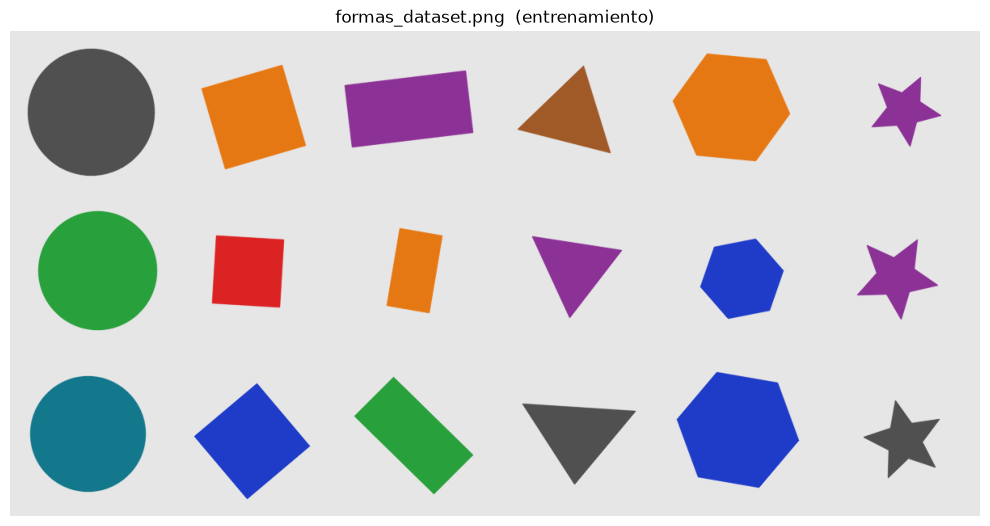

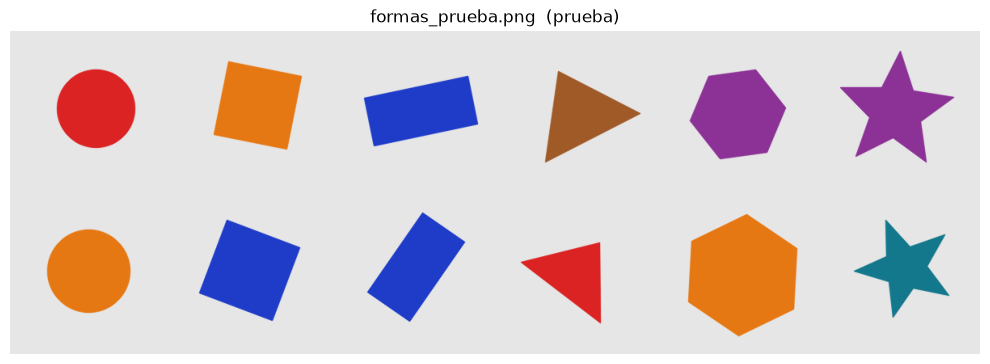

In [2]:
dataset = cv2.imread("imagenes/formas_dataset.png")
prueba = cv2.imread("imagenes/formas_prueba.png")
print("dataset:", dataset.shape, "  prueba:", prueba.shape)
print("Clases (una por columna):", CLASES)

mostrar(dataset, titulos=["formas_dataset.png  (entrenamiento)"], tam=10)
mostrar(prueba, titulos=["formas_prueba.png  (prueba)"], tam=10)

## 2. Binarizar y sacar regiones (repaso rápido)

Es exactamente el pipeline de la parte 1, ahora metido en una función para reusarlo con cualquier imagen:

1. gris
2. umbral de Otsu con `THRESH_BINARY_INV` (figuras en blanco)
3. apertura para quitar ruido
4. `measure.label` para numerar cada región

Regiones encontradas: 18


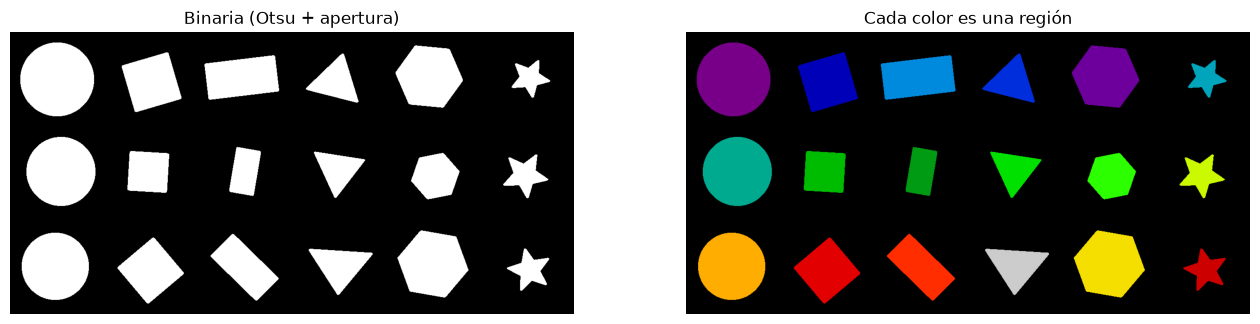

In [3]:
def segmentar(imagen):
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    _, binaria = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel)
    etiquetas = measure.label(binaria > 0, connectivity=2)
    return binaria, etiquetas


binaria, etiquetas = segmentar(dataset)
print("Regiones encontradas:", etiquetas.max())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
a1.imshow(binaria); a1.set_title("Binaria (Otsu + apertura)"); a1.axis("off")
a2.imshow(etiquetas, cmap="nipy_spectral"); a2.set_title("Cada color es una región"); a2.axis("off")
plt.show()

## 3. La tabla de características

Ahora medimos **todas** las regiones y guardamos cada una como un **renglón** de una tabla de pandas (`DataFrame`).

| Columna | Qué mide | ¿Depende del tamaño? | ¿Depende de la rotación? |
|---|---|---|---|
| área, perímetro | tamaño | sí | no |
| circularidad | 4π·área / perímetro² | no | no |
| extensión | área / área de la caja | no | **sí** |
| solidez | área / área del casco convexo | no | no |
| convexidad | perímetro del casco / perímetro | no | no |
| excentricidad | qué tan alargada es la elipse equivalente | no | no |
| relación de ejes | eje menor / eje mayor de la elipse (1 = "redonda") | no | no |

Nota que **ya no usamos la relación de aspecto de la caja** (ancho/alto) como en la parte 1: si giras un rectángulo 45°, su caja se vuelve casi cuadrada. La relación de ejes de la elipse no tiene ese problema.

La última columna, `clase`, es la **etiqueta**: la respuesta correcta. La sacamos de la columna en la que cae el centro de la figura.

In [4]:
def perimetro_casco(r):
    return measure.perimeter(np.pad(r.image_convex, 1))


def caracteristicas(imagen, area_minima=200):
    # Una fila por figura con sus descriptores de forma.
    _, etiquetas = segmentar(imagen)
    filas = []
    for r in measure.regionprops(etiquetas):
        if r.area < area_minima:          # ignora manchitas de ruido
            continue
        cy, cx = r.centroid
        filas.append({
            "x": cx,
            "y": cy,
            "área": r.area,
            "perímetro": r.perimeter,
            "circularidad": 4 * np.pi * r.area / r.perimeter**2,
            "extensión": r.extent,
            "solidez": r.solidity,
            "convexidad": perimetro_casco(r) / r.perimeter,
            "excentricidad": r.eccentricity,
            "relación_ejes": r.axis_minor_length / r.axis_major_length,
        })
    return pd.DataFrame(filas)


def etiquetar(tabla):
    # La clase verdadera sale de la columna de la imagen donde cae el centro.
    tabla = tabla.copy()
    tabla["clase"] = [CLASES[int(x // CELDA)] for x in tabla["x"]]
    return tabla


tabla = etiquetar(caracteristicas(dataset))
tabla

,x,y,área,perímetro,circularidad,extensión,solidez,convexidad,excentricidad,relación_ejes,clase
0,100.000,100.000,19421.0,520.902,0.899,0.788,0.992,0.996,0.000e+00,1.000,círculo
1,892.000,94.000,13899.0,457.789,0.833,0.731,0.987,1.000,5.464e-02,0.999,hexágono
2,301.000,106.000,10817.0,438.392,0.707,0.671,0.983,1.000,6.460e-03,1.000,cuadrado
3,693.023,104.724,5820.0,350.919,0.594,0.495,0.979,1.000,3.463e-01,0.938,triángulo
4,493.000,96.000,11805.0,470.024,0.671,0.782,0.983,1.000,8.574e-01,0.515,rectángulo
5,1106.084,97.027,3001.0,304.735,0.406,0.452,0.655,0.872,1.664e-01,0.986,estrella
6,108.001,296.001,16989.0,483.245,0.914,0.786,0.993,1.000,4.075e-05,1.000,círculo
7,500.000,296.000,5201.0,309.539,0.682,0.739,0.975,1.000,8.338e-01,0.552,rectángulo
8,294.000,297.000,7145.0,337.941,0.786,0.902,0.981,1.000,8.795e-03,1.000,cuadrado
9,697.977,292.919,5319.0,339.948,0.578,0.493,0.975,1.000,3.697e-01,0.929,triángulo


Eso de arriba **ya es un dataset de machine learning**:

- cada **renglón** es un ejemplo (una figura),
- cada **columna numérica** es una característica (*feature*),
- la columna `clase` es lo que queremos predecir.

Lo guardamos como CSV. Este archivo lo puedes abrir en Excel, y es el mismo formato que usarías con objetos reales (tornillos, frijoles, monedas…).

In [5]:
tabla.to_csv("formas_dataset.csv", index=False)
print("Guardé formas_dataset.csv con", len(tabla), "figuras y", tabla.shape[1], "columnas")

Guardé formas_dataset.csv con 18 figuras y 11 columnas


### Ubicar cada renglón en la imagen

Numeramos las figuras con el índice de la tabla para poder ir y venir entre la imagen y los números.

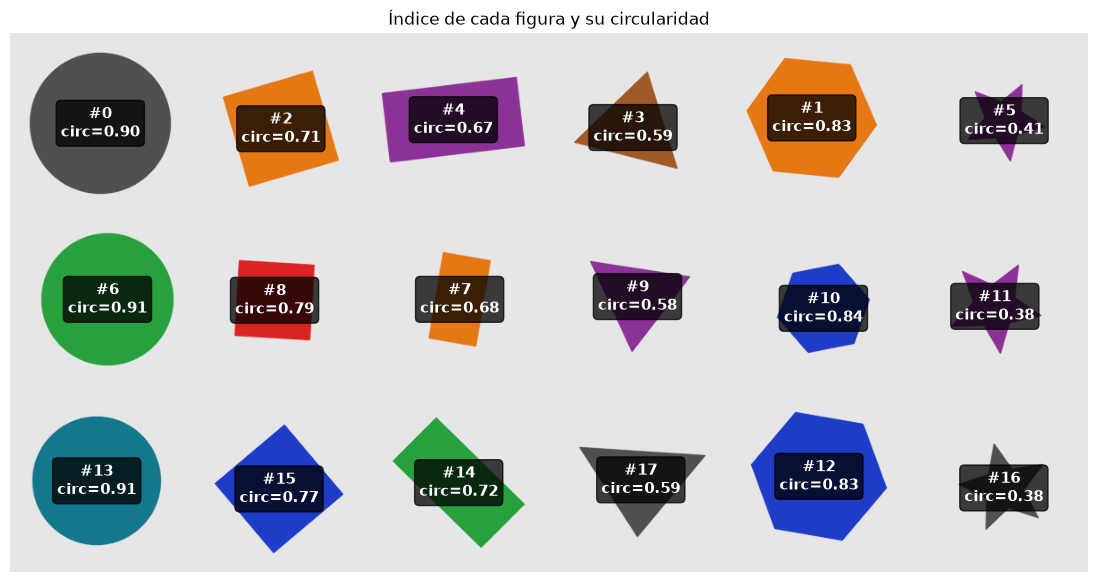

In [6]:
def anotar(imagen, tabla, textos, colores=None, titulo=""):
    fig, ax = plt.subplots(figsize=(14, 14 * imagen.shape[0] / imagen.shape[1]))
    ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    for i, (x, y) in enumerate(zip(tabla["x"], tabla["y"])):
        color = colores[i] if colores is not None else "k"
        ax.text(x, y, textos[i], ha="center", va="center", color="w", fontsize=11,
                weight="bold", bbox=dict(facecolor=color, alpha=0.75, boxstyle="round"))
    ax.set_title(titulo); ax.axis("off")
    plt.show()


anotar(dataset, tabla, [f"#{i}\ncirc={c:.2f}" for i, c in zip(tabla.index, tabla["circularidad"])],
       titulo="Índice de cada figura y su circularidad")

### Promedio por clase

Antes de clasificar, conviene **mirar los datos**. ¿Qué columna separa mejor cada clase?

In [7]:
columnas = ["área", "perímetro", "circularidad", "extensión", "solidez",
            "convexidad", "excentricidad", "relación_ejes"]

tabla.groupby("clase")[columnas].mean().loc[CLASES]

,área,perímetro,circularidad,extensión,solidez,convexidad,excentricidad,relación_ejes
clase,,,,,,,,
círculo,17511.667,492.026,0.908,0.788,0.992,0.999,1.358e-05,1.000
cuadrado,9458.333,396.238,0.754,0.699,0.984,1.000,2.065e-02,1.000
rectángulo,8837.667,395.848,0.690,0.660,0.984,1.000,8.523e-01,0.522
triángulo,5995.000,357.700,0.587,0.499,0.977,1.000,4.449e-01,0.884
hexágono,12135.000,422.408,0.835,0.715,0.986,1.000,9.233e-02,0.995
estrella,3500.000,336.258,0.389,0.441,0.639,0.867,1.323e-01,0.991


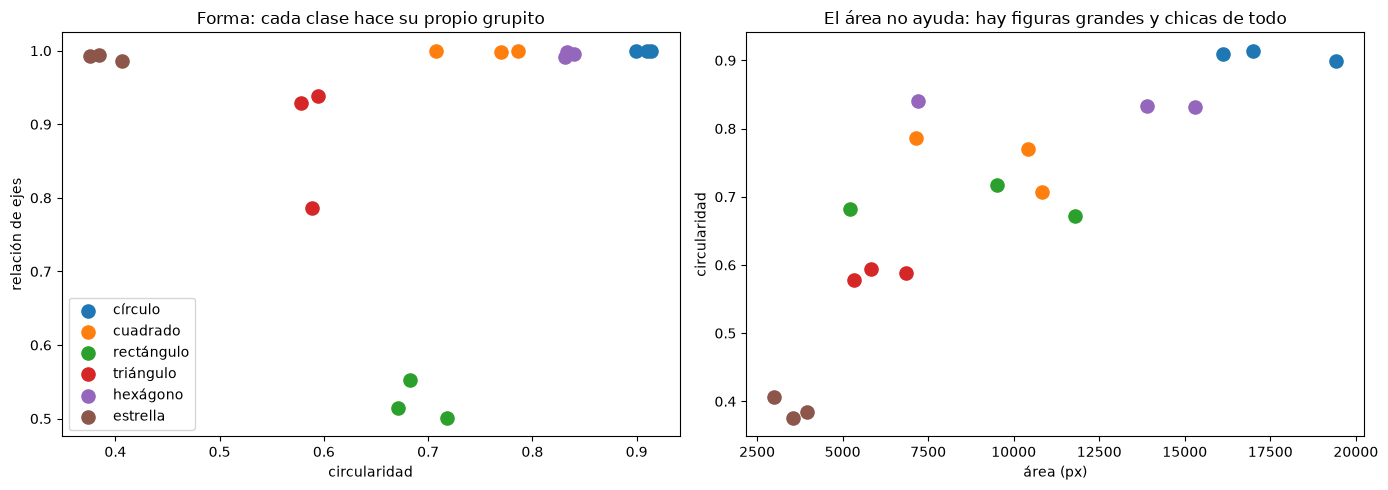

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for clase in CLASES:
    sub = tabla[tabla["clase"] == clase]
    ejes[0].scatter(sub["circularidad"], sub["relación_ejes"], s=90, label=clase)
    ejes[1].scatter(sub["área"], sub["circularidad"], s=90, label=clase)
ejes[0].set_xlabel("circularidad"); ejes[0].set_ylabel("relación de ejes")
ejes[0].set_title("Forma: cada clase hace su propio grupito")
ejes[1].set_xlabel("área (px)"); ejes[1].set_ylabel("circularidad")
ejes[1].set_title("El área no ayuda: hay figuras grandes y chicas de todo")
ejes[0].legend()
plt.tight_layout(); plt.show()

Lo que se ve:

- La **circularidad** ordena casi todo: círculo (~0.9) > hexágono (~0.83) > cuadrado y rectángulo (~0.7) > triángulo (~0.56) > estrella (~0.35).
- Cuadrado y rectángulo se **enciman** en circularidad, pero la **relación de ejes** los separa (1 contra ~0.5).
- El **área** está revuelta: no sirve para saber la forma.

## 4. Clasificar con reglas (a mano)

### 4.1 Solo con circularidad

La idea más directa: *si la circularidad es tal, imprime "círculo"*.

In [9]:
for i, f in tabla.iterrows():
    c = f["circularidad"]
    if c > 0.87:
        forma = "círculo"
    elif c > 0.80:
        forma = "hexágono"
    elif c > 0.63:
        forma = "cuadrado"
    elif c > 0.45:
        forma = "triángulo"
    else:
        forma = "estrella"
    marca = "✓" if forma == f["clase"] else "✗"
    print(f"#{i:<3} circularidad = {c:.2f}  →  {forma:<10} (es {f['clase']}) {marca}")

#0   circularidad = 0.90  →  círculo    (es círculo) ✓
#1   circularidad = 0.83  →  hexágono   (es hexágono) ✓
#2   circularidad = 0.71  →  cuadrado   (es cuadrado) ✓
#3   circularidad = 0.59  →  triángulo  (es triángulo) ✓
#4   circularidad = 0.67  →  cuadrado   (es rectángulo) ✗
#5   circularidad = 0.41  →  estrella   (es estrella) ✓
#6   circularidad = 0.91  →  círculo    (es círculo) ✓
#7   circularidad = 0.68  →  cuadrado   (es rectángulo) ✗
#8   circularidad = 0.79  →  cuadrado   (es cuadrado) ✓
#9   circularidad = 0.58  →  triángulo  (es triángulo) ✓
#10  circularidad = 0.84  →  hexágono   (es hexágono) ✓
#11  circularidad = 0.38  →  estrella   (es estrella) ✓
#12  circularidad = 0.83  →  hexágono   (es hexágono) ✓
#13  circularidad = 0.91  →  círculo    (es círculo) ✓
#14  circularidad = 0.72  →  cuadrado   (es rectángulo) ✗
#15  circularidad = 0.77  →  cuadrado   (es cuadrado) ✓
#16  circularidad = 0.38  →  estrella   (es estrella) ✓
#17  circularidad = 0.59  →  triángulo  (es

Casi todo sale bien, pero **los rectángulos salen como cuadrados**: con un solo número no alcanza. Necesitamos una segunda característica.

### 4.2 Reglas con varias características

In [10]:
def clasificar_reglas(f):
    if f["solidez"] < 0.8:              # tiene entrantes (picos)
        return "estrella"
    if f["circularidad"] > 0.87:
        return "círculo"
    if f["circularidad"] > 0.80:
        return "hexágono"
    if f["relación_ejes"] < 0.65:       # alargado
        return "rectángulo"
    if f["circularidad"] < 0.63:
        return "triángulo"
    return "cuadrado"


tabla["reglas"] = tabla.apply(clasificar_reglas, axis=1)
aciertos = (tabla["reglas"] == tabla["clase"]).mean()
print(f"Exactitud en el dataset: {aciertos:.0%}")
tabla[["circularidad", "solidez", "relación_ejes", "clase", "reglas"]]

Exactitud en el dataset: 100%


,circularidad,solidez,relación_ejes,clase,reglas
0,0.899,0.992,1.000,círculo,círculo
1,0.833,0.987,0.999,hexágono,hexágono
2,0.707,0.983,1.000,cuadrado,cuadrado
3,0.594,0.979,0.938,triángulo,triángulo
4,0.671,0.983,0.515,rectángulo,rectángulo
5,0.406,0.655,0.986,estrella,estrella
6,0.914,0.993,1.000,círculo,círculo
7,0.682,0.975,0.552,rectángulo,rectángulo
8,0.786,0.981,1.000,cuadrado,cuadrado
9,0.578,0.975,0.929,triángulo,triángulo


¡100%! Pero ojo: estos umbrales los elegimos **viendo estas mismas 18 figuras**. La pregunta importante es si funcionan con figuras **nuevas**. Para eso está la imagen de prueba.

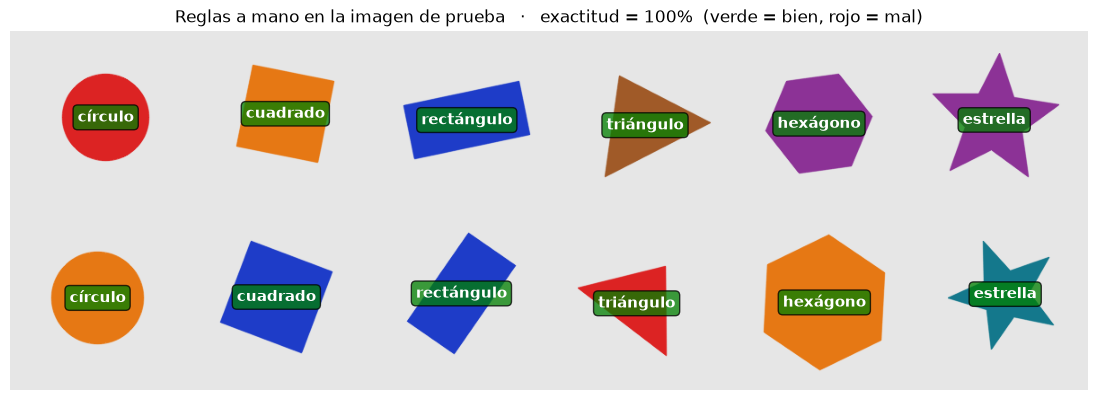

In [11]:
tabla_prueba = etiquetar(caracteristicas(prueba))
pred = tabla_prueba.apply(clasificar_reglas, axis=1)


def evaluar(imagen, tabla, pred, titulo):
    ok = (pred.values == tabla["clase"].values)
    anotar(imagen, tabla, list(pred), colores=np.where(ok, "green", "red"),
           titulo=f"{titulo}   ·   exactitud = {ok.mean():.0%}  (verde = bien, rojo = mal)")
    return ok.mean()


evaluar(prueba, tabla_prueba, pred, "Reglas a mano en la imagen de prueba");

### ¿Y las reglas de la parte 1?

En la parte 1 usamos `extensión > 0.9 → cuadrado`. Mira la extensión de nuestros cuadrados: depende de cuánto estén **girados**.

In [12]:
tabla[tabla["clase"] == "cuadrado"][["extensión", "relación_ejes"]]

,extensión,relación_ejes
2,0.671,1.000
8,0.902,1.000
15,0.524,0.999


Un cuadrado derecho llena su caja (≈1), pero uno girado 45° solo la mitad (≈0.5). Por eso elegir bien las características importa tanto como el clasificador.

### El problema de las reglas a mano

Funcionan, pero:

- **tú** tuviste que mirar los números y elegir cada umbral,
- si agregas una clase nueva (elipse, pentágono…) hay que reacomodar todo,
- con 10 clases y 20 características se vuelve imposible.

Aquí entra el **machine learning**: le damos la tabla con las respuestas correctas y el algoritmo **encuentra las reglas solo**.

---

## 5. Machine learning: lo mínimo

Lo que vamos a hacer se llama **clasificación supervisada**: "supervisada" porque le damos ejemplos **con la respuesta**.

| Nombre | Qué es | En nuestro caso |
|---|---|---|
| `X` | matriz de características (una fila por ejemplo) | las columnas numéricas de la tabla |
| `y` | etiquetas (la respuesta correcta) | la columna `clase` |
| entrenamiento | ejemplos con los que el modelo aprende | `formas_dataset.png` (18 figuras) |
| prueba | ejemplos que el modelo **nunca vio**, para medir qué tan bien generaliza | `formas_prueba.png` (12 figuras) |
| exactitud (*accuracy*) | % de predicciones correctas | |

En **scikit-learn** todos los modelos se usan igual:

```python
modelo = AlgunModelo(parámetros)
modelo.fit(X_entrenamiento, y_entrenamiento)   # aprender
modelo.predict(X_nuevo)                         # predecir
```

Así que una vez que entiendes uno, puedes probar cualquier otro cambiando una línea.

Vamos a usar dos juegos de características:

- `columnas`: **todas** (las 8), incluyendo área y perímetro.
- `forma`: solo las que **no dependen del tamaño** (las 6 que son cocientes).

Empezamos con todas, como haría cualquiera que no se puso a pensar en cuáles sirven… y vemos qué pasa.

In [13]:
forma = ["circularidad", "extensión", "solidez", "convexidad", "excentricidad", "relación_ejes"]

X_train = tabla[columnas]
y_train = tabla["clase"]
X_test = tabla_prueba[columnas]
y_test = tabla_prueba["clase"]

print("X_train:", X_train.shape, "   X_test:", X_test.shape)
resultados = {"Reglas a mano": (tabla_prueba.apply(clasificar_reglas, axis=1) == y_test).mean()}

X_train: (18, 8)    X_test: (12, 8)


## 6. Árbol de decisión

**Idea:** un árbol de decisión es un montón de `if / else` anidados, como nuestras reglas… pero **los elige solo**.

En cada paso prueba todas las preguntas posibles del tipo *"¿circularidad ≤ 0.75?"* y se queda con la que **mejor separa** las clases (la que deja grupos más "puros", con una sola clase). Luego repite con cada grupo hasta que todos son puros o llega a la profundidad máxima.

- ✅ Se puede **leer**: puedes ver exactamente qué reglas aprendió.
- ✅ No le importa la escala de las características.
- ⚠️ Si lo dejas crecer sin límite, se aprende de memoria el dataset (*sobreajuste*).

In [14]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

arbol = DecisionTreeClassifier(random_state=0)
arbol.fit(X_train, y_train)

print(export_text(arbol, feature_names=columnas))

|--- relación_ejes <= 0.67
|   |--- class: rectángulo
|--- relación_ejes >  0.67
|   |--- excentricidad <= 0.00
|   |   |--- class: círculo
|   |--- excentricidad >  0.00
|   |   |--- área <= 6995.50
|   |   |   |--- relación_ejes <= 0.96
|   |   |   |   |--- class: triángulo
|   |   |   |--- relación_ejes >  0.96
|   |   |   |   |--- class: estrella
|   |   |--- área >  6995.50
|   |   |   |--- circularidad <= 0.81
|   |   |   |   |--- class: cuadrado
|   |   |   |--- circularidad >  0.81
|   |   |   |   |--- class: hexágono



Estas son las reglas que encontró **solo**. Compáralas con las de la sección 4: algunas preguntas se parecen (la relación de ejes para los rectángulos, la circularidad para el hexágono)… pero hay una sospechosa: **usó el área**. Veamos cómo le va con la imagen de prueba.

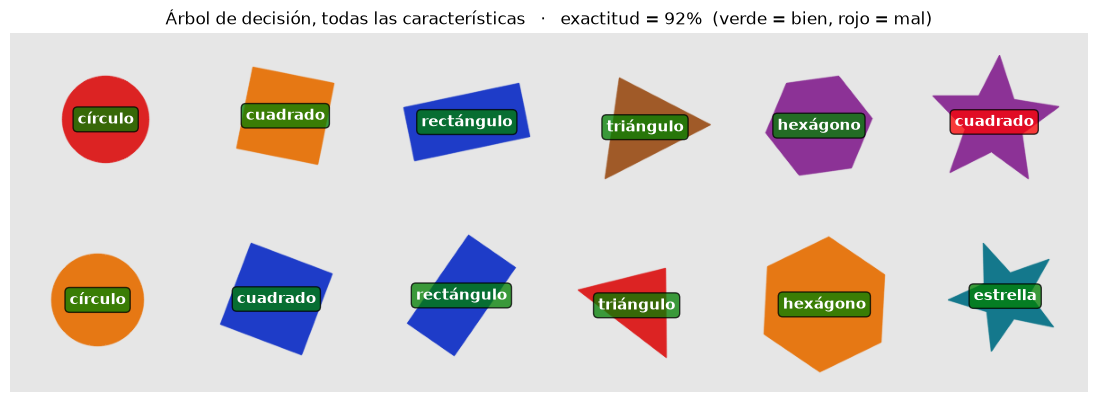

In [15]:
pred = arbol.predict(X_test)
resultados["Árbol (todas)"] = evaluar(prueba, tabla_prueba, pd.Series(pred), "Árbol de decisión, todas las características")

### El árbol aprendió una casualidad

En las 18 figuras de entrenamiento, **por pura suerte**, las estrellas y los triángulos salieron chiquitos. El árbol encontró que *"área pequeña → estrella o triángulo"* separaba perfecto sus datos… y se lo creyó. En la imagen de prueba aparece una estrella **grande** y el árbol se equivoca.

El modelo no sabe qué es casualidad y qué no: solo ve números. Esto pasa muchísimo con pocos datos, y por eso:

1. hay que **probar siempre con datos que el modelo no vio**, y
2. vale la pena **elegir características que tengan sentido** para el problema. Sabemos que la forma no depende del tamaño, así que quitemos área y perímetro.

|--- extensión <= 0.46
|   |--- class: estrella
|--- extensión >  0.46
|   |--- relación_ejes <= 0.67
|   |   |--- class: rectángulo
|   |--- relación_ejes >  0.67
|   |   |--- circularidad <= 0.81
|   |   |   |--- solidez <= 0.98
|   |   |   |   |--- class: triángulo
|   |   |   |--- solidez >  0.98
|   |   |   |   |--- class: cuadrado
|   |   |--- circularidad >  0.81
|   |   |   |--- extensión <= 0.76
|   |   |   |   |--- class: hexágono
|   |   |   |--- extensión >  0.76
|   |   |   |   |--- class: círculo



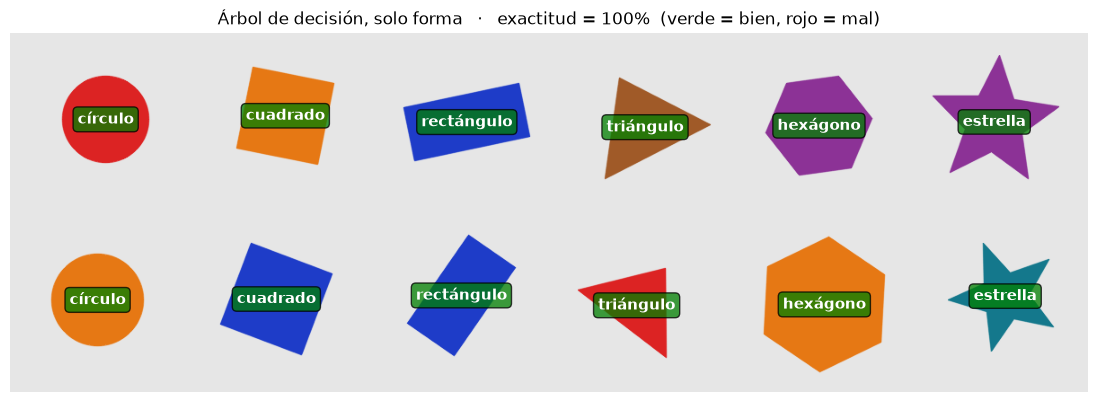

In [16]:
arbol = DecisionTreeClassifier(random_state=0)
arbol.fit(X_train[forma], y_train)
print(export_text(arbol, feature_names=forma))

pred = arbol.predict(X_test[forma])
resultados["Árbol (forma)"] = evaluar(prueba, tabla_prueba, pd.Series(pred), "Árbol de decisión, solo forma")

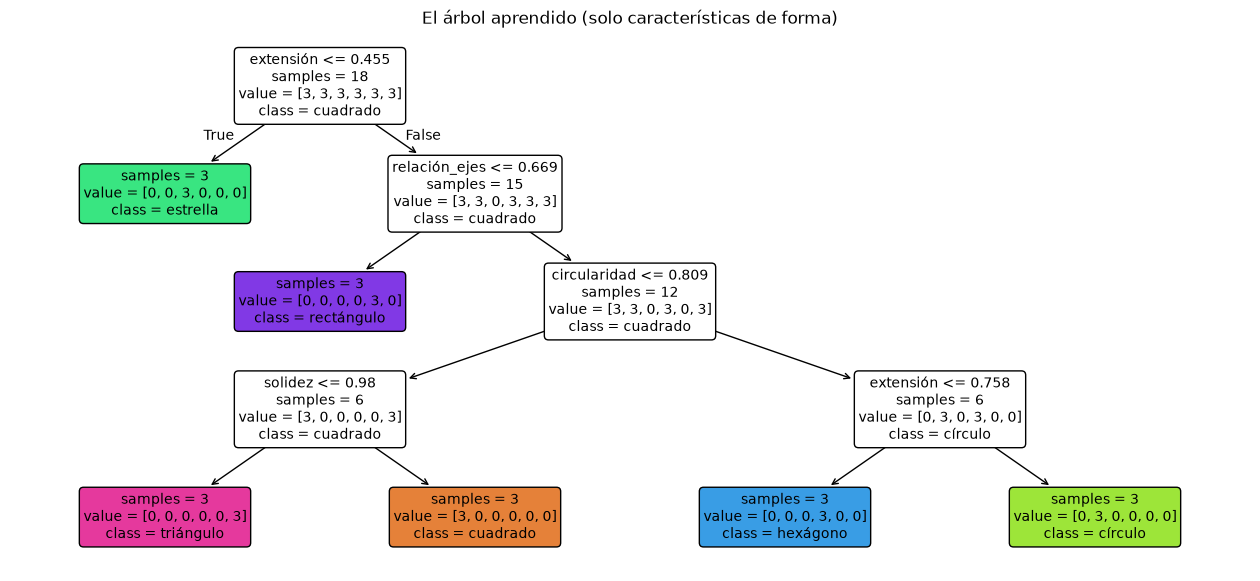

In [17]:
plt.figure(figsize=(16, 7))
plot_tree(arbol, feature_names=forma, class_names=arbol.classes_, filled=True,
          rounded=True, fontsize=10, impurity=False)
plt.title("El árbol aprendido (solo características de forma)")
plt.show()

Cada caja muestra la pregunta, cuántos ejemplos llegaron ahí (`samples`) y cuántos hay de cada clase (`value`, en orden alfabético: el de `arbol.classes_`). Las hojas de abajo son la respuesta final.

Ojo con la pregunta que separa **triángulo de cuadrado**: usa la solidez con un margen chiquitísimo (los triángulos andan en ~0.977 y los cuadrados en ~0.984). Nosotros usamos la circularidad, que los separa con mucha más holgura (~0.58 contra ~0.75). El árbol se queda con **la primera pregunta que separa perfecto** sus datos, no necesariamente con la más robusta. Con figuras nuevas, una regla así de justa puede fallar. Esto lo arregla el Random Forest (sección 8).

## 7. k vecinos más cercanos (k-NN)

**Idea:** para clasificar una figura nueva, busca las **k figuras más parecidas** del entrenamiento y hace una **votación**. "Dime con quién andas y te diré quién eres."

"Parecidas" quiere decir **cerca** en el espacio de características, usando la distancia euclidiana:

$$ d(a, b) = \sqrt{(a_1 - b_1)^2 + (a_2 - b_2)^2 + \dots} $$

- ✅ Es el algoritmo más fácil de entender. No "aprende" nada: solo **memoriza** los ejemplos.
- ⚠️ Es **muy sensible a la escala** de las características. Veamos por qué.

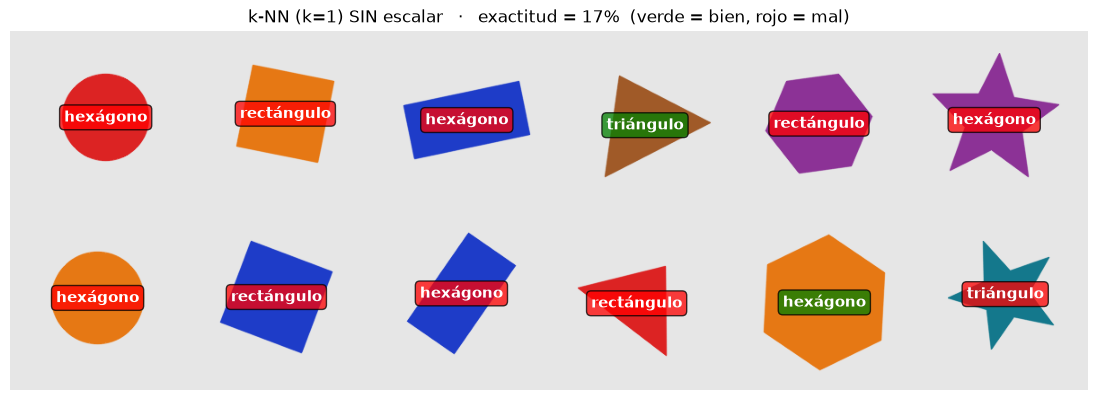

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

pred = knn.predict(X_test)
resultados["k-NN sin escalar"] = evaluar(prueba, tabla_prueba, pd.Series(pred), "k-NN (k=1) SIN escalar")

¿Qué pasó? Mira los rangos de cada columna:

In [19]:
X_train.describe().loc[["min", "max"]]

,área,perímetro,circularidad,extensión,solidez,convexidad,excentricidad,relación_ejes
min,3001.0,304.735,0.375,0.432,0.627,0.861,0.000,0.501
max,19421.0,520.902,0.914,0.902,0.994,1.000,0.866,1.000


El **área** va de miles a decenas de miles; la **circularidad** de 0.3 a 0.9. En la fórmula de la distancia, una diferencia de 5000 px de área aplasta a cualquier diferencia de circularidad. El k-NN termina buscando "la figura de **tamaño** más parecido", no la de **forma** más parecida.

**Solución:** escalar cada columna para que todas tengan la misma importancia. `StandardScaler` le resta la media y divide entre la desviación estándar:

$$ z = \frac{x - \mu}{\sigma} $$

Con un `Pipeline`, el escalado se aprende con los datos de entrenamiento y se aplica solito antes de predecir.

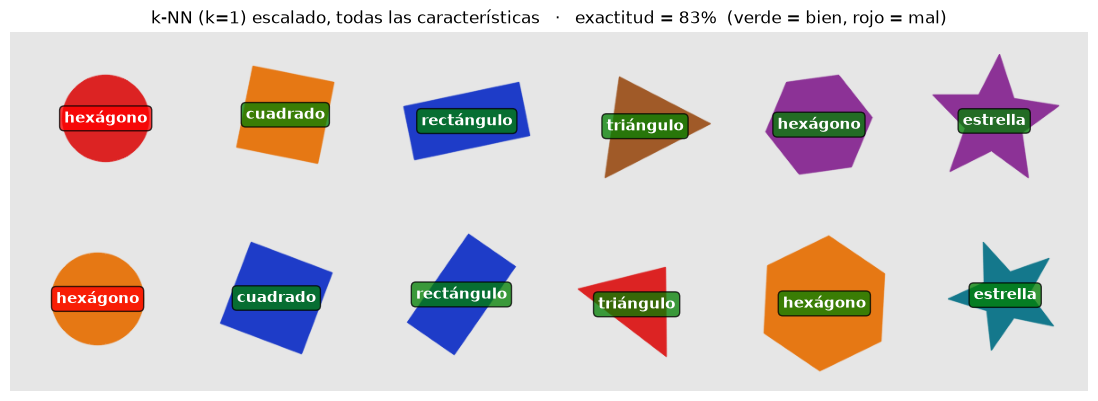

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn_escalado = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
knn_escalado.fit(X_train, y_train)

pred = knn_escalado.predict(X_test)
resultados["k-NN escalado (todas)"] = evaluar(prueba, tabla_prueba, pd.Series(pred), "k-NN (k=1) escalado, todas las características")

Mucho mejor, pero todavía falla. Ahora el área ya no aplasta a las demás… pero **sigue contando igual** que cualquier otra columna. Los círculos de prueba son chicos, y por tamaño se parecen a los hexágonos chicos del entrenamiento.

Igual que con el árbol: quitemos las características que no tienen que ver con la forma.

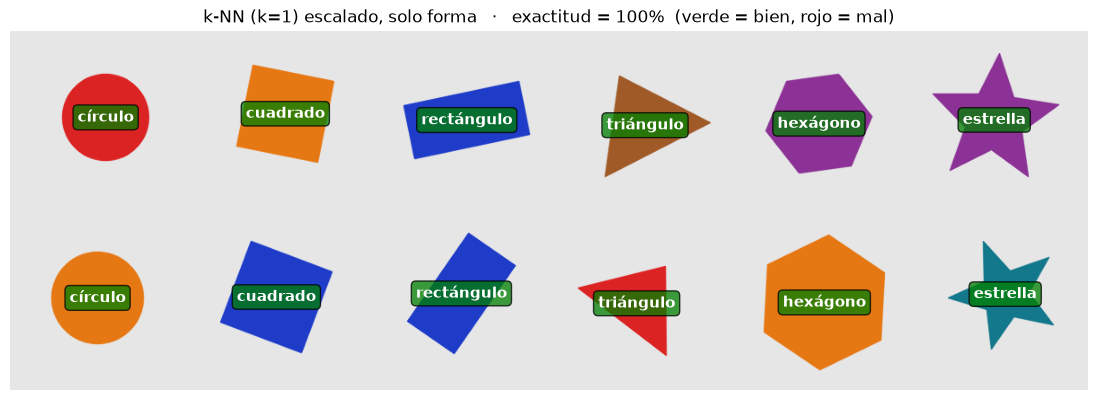

In [21]:
knn_forma = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
knn_forma.fit(X_train[forma], y_train)

pred = knn_forma.predict(X_test[forma])
resultados["k-NN escalado (forma)"] = evaluar(prueba, tabla_prueba, pd.Series(pred), "k-NN (k=1) escalado, solo forma")

**Moraleja:** el algoritmo fue el mismo las tres veces. Lo que cambió fue **cómo le presentamos los datos**: escalarlos y elegir las características correctas.

### ¿Qué k elegir?

Con `k = 1` decide el vecino más cercano y ya. Con `k` más grande vota más gente y es más robusto al ruido… pero ojo: **solo tenemos 3 ejemplos por clase**. Si `k = 7`, al menos 4 votos vienen forzosamente de **otras** clases.

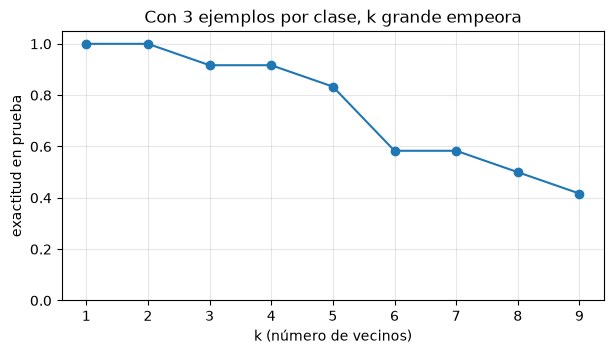

In [22]:
ks = range(1, 10)
exactitudes = []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train[forma], y_train)
    exactitudes.append((m.predict(X_test[forma]) == y_test).mean())

plt.figure(figsize=(7, 3.5))
plt.plot(list(ks), exactitudes, "o-")
plt.xlabel("k (número de vecinos)"); plt.ylabel("exactitud en prueba")
plt.title("Con 3 ejemplos por clase, k grande empeora"); plt.ylim(0, 1.05); plt.grid(alpha=0.3)
plt.show()

### Cómo se ven las fronteras

Para poder dibujarlo, entrenamos un k-NN con **solo dos** características (circularidad y relación de ejes). Cada color de fondo es la clase que el modelo le daría a una figura nueva que cayera en ese punto.

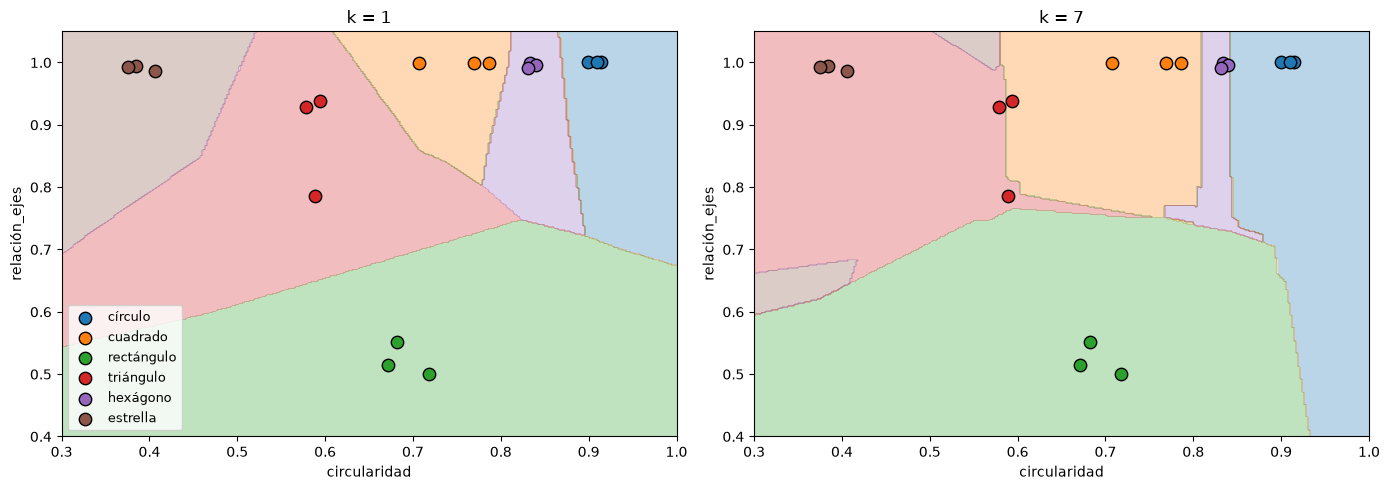

In [23]:
dos = ["circularidad", "relación_ejes"]
codigos = {c: i for i, c in enumerate(CLASES)}
colores = [plt.cm.tab10(i) for i in range(len(CLASES))]

# Una rejilla de puntos "falsos" que cubre la gráfica; el modelo clasifica cada uno
xx, yy = np.meshgrid(np.linspace(0.3, 1.0, 300), np.linspace(0.4, 1.05, 300))
rejilla = pd.DataFrame({dos[0]: xx.ravel(), dos[1]: yy.ravel()})

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, k in zip(ejes, [1, 7]):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    m.fit(tabla[dos], tabla["clase"].map(codigos))
    zona = m.predict(rejilla).reshape(xx.shape)
    ax.contourf(xx, yy, zona, levels=np.arange(-0.5, len(CLASES)), colors=colores, alpha=0.3)
    for c in CLASES:
        sub = tabla[tabla["clase"] == c]
        ax.scatter(sub[dos[0]], sub[dos[1]], s=80, ec="k", color=colores[codigos[c]], label=c)
    ax.set_title(f"k = {k}"); ax.set_xlabel(dos[0]); ax.set_ylabel(dos[1])
ejes[0].legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()

Con `k = 1` cada clase tiene su zona. Con `k = 7` las zonas de las clases que están solitas (como la estrella) **se encogen o casi desaparecen**: aunque tengan 3 votos, los otros 4 vecinos son de otras clases y pierden la votación.

## 8. Random Forest (bosque aleatorio)

**Idea:** un árbol solo puede equivocarse por mala suerte en los datos. ¿Y si entrenamos **muchos** árboles distintos y que voten?

Para que los árboles no salgan todos iguales, cada uno se entrena:
1. con una **muestra al azar** del dataset (con reemplazo, así que algunos ejemplos se repiten y otros faltan),
2. y en cada pregunta solo puede elegir entre **algunas características al azar**.

Al final, gana la clase con más votos.

- ✅ Suele funcionar muy bien "de fábrica", sin ajustar casi nada.
- ✅ Nos dice **qué características fueron más útiles**.
- ⚠️ Ya no se puede leer como un solo árbol (son 100).

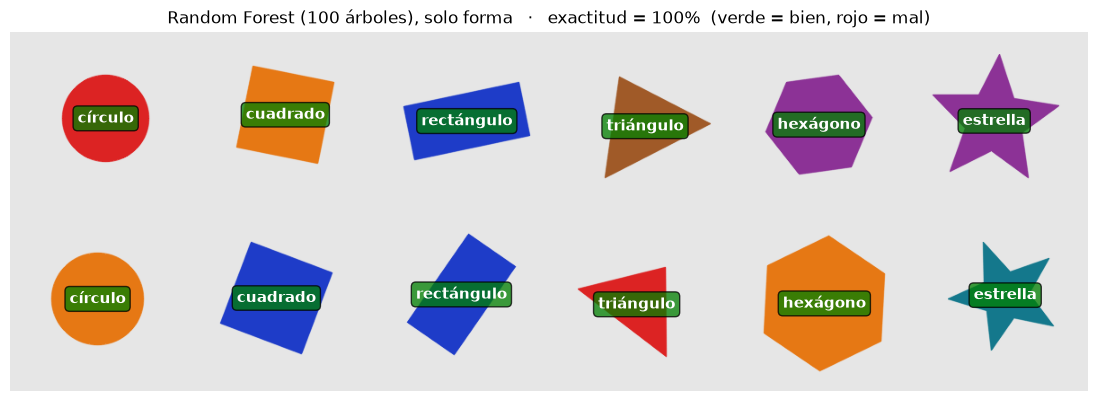

In [24]:
from sklearn.ensemble import RandomForestClassifier

bosque = RandomForestClassifier(n_estimators=100, random_state=0)
bosque.fit(X_train[forma], y_train)

pred = bosque.predict(X_test[forma])
resultados["Random Forest (forma)"] = evaluar(prueba, tabla_prueba, pd.Series(pred), "Random Forest (100 árboles), solo forma")

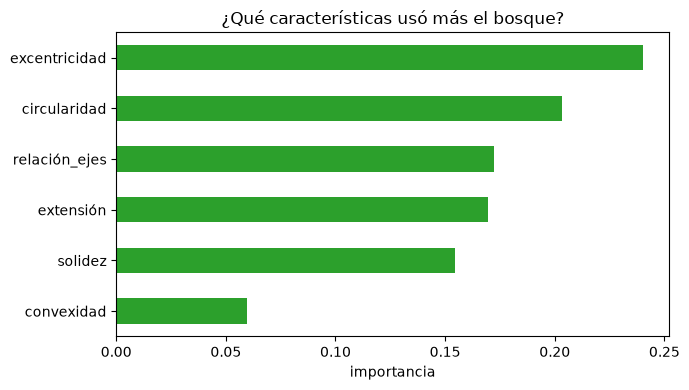

In [25]:
importancia = pd.Series(bosque.feature_importances_, index=forma).sort_values()
importancia.plot.barh(figsize=(7, 4), color="tab:green")
plt.title("¿Qué características usó más el bosque?"); plt.xlabel("importancia")
plt.tight_layout(); plt.show()

La importancia dice cuánto ayudó cada característica a separar las clases, sumando todos los árboles. Compárala con lo que vimos en las gráficas de la sección 3.

Además de la clase, el bosque puede decir **qué tan seguro** está: el porcentaje de árboles que votó por cada clase.

In [26]:
probas = pd.DataFrame(bosque.predict_proba(X_test[forma]), columns=bosque.classes_)
probas.insert(0, "verdadera", y_test.values)
probas.style.format(precision=2, subset=list(bosque.classes_)).background_gradient(
    cmap="Greens", subset=list(bosque.classes_), vmin=0, vmax=1)

,verdadera,cuadrado,círculo,estrella,hexágono,rectángulo,triángulo
0,estrella,0.22,0.00,0.76,0.00,0.00,0.02
1,cuadrado,0.70,0.01,0.00,0.20,0.08,0.01
2,círculo,0.00,0.97,0.00,0.03,0.00,0.00
3,hexágono,0.28,0.01,0.00,0.71,0.00,0.00
4,triángulo,0.00,0.00,0.02,0.00,0.06,0.92
5,rectángulo,0.07,0.00,0.00,0.01,0.60,0.32
6,rectángulo,0.05,0.00,0.01,0.02,0.69,0.23
7,hexágono,0.02,0.01,0.02,0.92,0.03,0.00
8,cuadrado,0.86,0.05,0.00,0.04,0.03,0.02
9,estrella,0.00,0.00,0.97,0.00,0.00,0.03


## 9. Comparación

Reglas a mano            100%
Árbol (todas)             92%
Árbol (forma)            100%
k-NN sin escalar          17%
k-NN escalado (todas)     83%
k-NN escalado (forma)    100%
Random Forest (forma)    100%


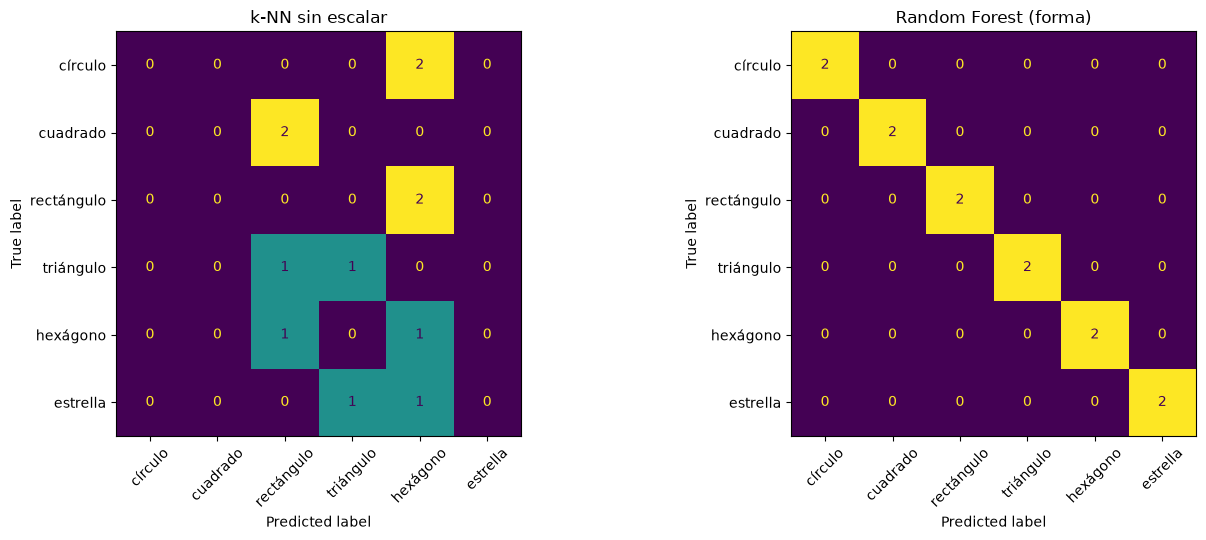

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

print(pd.Series(resultados, name="exactitud en prueba").map("{:.0%}".format).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (nombre, m, cols) in zip(ejes, [("k-NN sin escalar", knn, columnas),
                                       ("Random Forest (forma)", bosque, forma)]):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test[cols]), labels=CLASES, ax=ax,
                                            colorbar=False, xticks_rotation=45)
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

La **matriz de confusión** dice en qué se equivoca cada modelo: los renglones son la clase verdadera y las columnas la predicha. Todo lo que no esté en la diagonal es un error. En el k-NN sin escalar se ve qué clases confunde; en el bosque todo cae en la diagonal.

Fíjate en la tabla de exactitudes: **las características importaron más que el algoritmo**. Los tres algoritmos llegan al 100% cuando les damos las características correctas.

| Algoritmo | ¿Cómo decide? | Necesita escalar | Se puede leer |
|---|---|---|---|
| Reglas a mano | umbrales que tú eliges | no | sí |
| Árbol de decisión | umbrales que **él** elige | no | sí |
| k-NN | votación de los vecinos más parecidos | **sí** | más o menos (ves los vecinos) |
| Random Forest | votación de muchos árboles | no | no del todo (sí la importancia) |

## 10. Usar el modelo con una imagen nueva

Juntamos todo en una función: imagen → características → predicción. Ya **no hay etiquetas**: es justo como se usaría en la vida real.

Probamos con una imagen nueva generada con otra semilla y con la imagen de la parte 1.

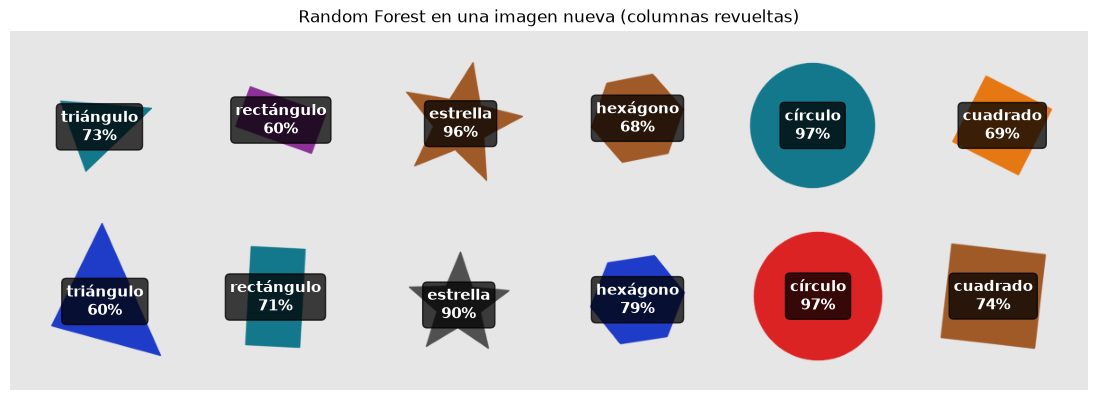

In [28]:
def predecir_imagen(imagen, modelo, titulo=""):
    t = caracteristicas(imagen)
    pred = modelo.predict(t[forma])
    seguridad = modelo.predict_proba(t[forma]).max(axis=1)
    anotar(imagen, t, [f"{p}\n{s:.0%}" for p, s in zip(pred, seguridad)], titulo=titulo)
    return t


nueva = generar(por_clase=2, semilla=42)
# revolvemos las columnas para que la posición no "delate" la clase
columnas_img = np.split(nueva, len(CLASES), axis=1)
np.random.default_rng(0).shuffle(columnas_img)
nueva = np.hstack(columnas_img)

predecir_imagen(nueva, bosque, "Random Forest en una imagen nueva (columnas revueltas)");

El número debajo de cada predicción es la **seguridad** del bosque (qué porcentaje de árboles votó por esa clase).

### ¿Y con algo distinto a lo que vio?

Ahora la imagen de la parte 1. Ojo con dos cosas: su "cuadrado" en realidad mide 220 × 240 px (ni cuadrado perfecto ni rectángulo alargado como los del entrenamiento), y su triángulo es más chato que los que vio el modelo.

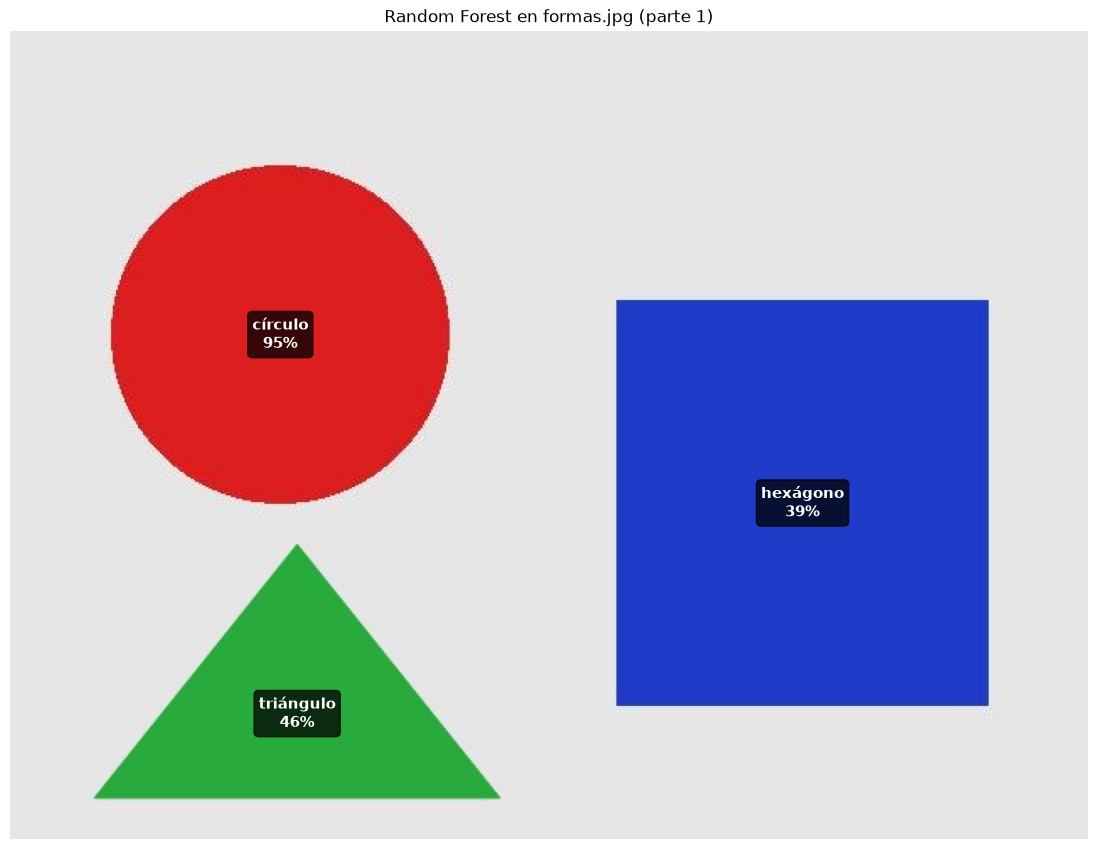

,circularidad,extensión,solidez,convexidad,excentricidad,relación_ejes
0,0.909,0.784,0.994,1.0,0.000,1.000
1,0.795,1.000,1.000,1.0,0.399,0.917
2,0.577,0.515,0.993,1.0,0.692,0.722


In [29]:
t1 = predecir_imagen(cv2.imread("imagenes/formas.jpg"), bosque, "Random Forest en formas.jpg (parte 1)")
t1[forma]

El círculo sale bien y con mucha seguridad. El triángulo sale bien, pero dudando. Y el "cuadrado" sale **mal** y con poca seguridad: con circularidad ~0.8 y excentricidad ~0.4 no se parece a ninguna figura del entrenamiento (los cuadrados que vio tienen excentricidad 0 y los rectángulos son mucho más alargados).

Cuando una figura no se parece a **nada** de lo que el modelo vio, el modelo **igual contesta algo**: no sabe decir "no sé". La pista es la **seguridad baja**: los árboles no se pusieron de acuerdo.

En la práctica:

- si la seguridad es baja, **no le creas** (o márcalo para que lo revise una persona),
- y la solución de fondo es **agregar ejemplos parecidos al entrenamiento**. Un modelo solo sabe lo que le enseñaste.

## Para practicar

1. **Sobreajuste.** Entrena el árbol con `max_depth=2`. ¿Cuántas clases alcanza a distinguir? ¿Qué preguntas eligió?
2. **Más datos.** Corre `uv run generar_formas.py mas_formas.png 10 5` para hacer 10 ejemplos por clase, úsala como entrenamiento y repite la gráfica de k. ¿Ahora sí conviene un k grande?
3. **Clase nueva.** Agrega `"elipse"` a `CLASES` en `generar_formas.py` (con `cv2.ellipse`). ¿Tus reglas a mano siguen funcionando? ¿Y el Random Forest?
4. **Quita características.** Entrena el k-NN escalado solo con `["área", "perímetro"]`. ¿Qué pasa? ¿Y solo con `["circularidad"]`?
5. **Tus propios objetos.** Toma una foto de objetos sobre una hoja blanca, etiqueta a mano el CSV y entrena un modelo. ¿Qué características separan mejor tus clases?
6. **Otro algoritmo.** Cambia `RandomForestClassifier` por `SVC(probability=True)` de `sklearn.svm` (con `StandardScaler`). Solo cambia una línea.